In [71]:
# Task 2: Data Cleaning & Preprocessing
# Prepare the raw web-scraped data for analysis by handling missing values, standardizing data types, removing duplicates, and engineering new features.

In [73]:
import pandas as pd
import numpy as np

# Load the scraped dataset and strip hidden whitespace from column names
df = pd.read_csv(r"C:\Users\dell\Web_t20i_players.csv")
df.columns = df.columns.str.strip() 

print(f"Data loaded successfully! Shape: {df.shape}")

Data loaded successfully! Shape: (3762, 13)


In [5]:
# checking the columns and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3762 entries, 0 to 3761
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   player        3762 non-null   str    
 1   team          3762 non-null   str    
 2   year          3762 non-null   int64  
 3   matches       3762 non-null   int64  
 4   inns          2200 non-null   float64
 5   runs          2200 non-null   float64
 6   balls         2200 non-null   float64
 7   average       2200 non-null   str    
 8   strike_rate   2200 non-null   float64
 9   wickets       2200 non-null   str    
 10  bowl_average  2200 non-null   str    
 11  economy       2200 non-null   str    
 12  overs         2200 non-null   str    
dtypes: float64(4), int64(2), str(7)
memory usage: 470.7 KB


In [6]:
# taking a quick look at the actual data
display(df.head(1000))

,player,team,year,matches,inns,runs,balls,average,strike_rate,wickets,bowl_average,economy,overs
0,A Ahmadhel,BUL,2020,3,NaN,NaN,NaN,NaN,NaN,3,16.33,10.5,4.4
1,A Ashokan,CZK-R,2020,4,4.0,51.0,54.0,12.75,94.44,2,48.5,10.98,8.5
2,A Ashokan,CZK-R,2021,7,7.0,151.0,140.0,30.2,107.85,NaN,NaN,NaN,NaN
3,A Ashokan,CZK-R,2022,15,14.0,369.0,299.0,36.9,123.41,11,28.27,7.77,40.0
4,A Athanaze,WI,2025,10,10.0,251.0,191.0,25.1,131.41,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,F Nsubuga,UGA,2020,3,NaN,NaN,NaN,NaN,NaN,2,36.5,6.08,12.0
996,F Nsubuga,UGA,2021,14,NaN,NaN,NaN,NaN,NaN,15,13.6,3.92,52.0
997,F Nsubuga,UGA,2022,24,NaN,NaN,NaN,NaN,NaN,26,15,4.88,79.5
998,F Nsubuga,UGA,2023,10,NaN,NaN,NaN,NaN,NaN,10,16.9,5.28,32.0


In [ ]:
# Handling Inconsistent Formats & Data Types
# Web scraped data often contains text placeholders (like `-`) for missing numeric values. 
# We need to convert these to structural NaNs and cast the columns to float for mathematical operations.

In [74]:
# Replace web scraping placeholders ('-') with actual NaNs
df.replace('-', np.nan, inplace=True)

# Convert string columns that should be numbers into floats
cols_to_convert = ['average', 'wickets', 'bowl_average', 'economy', 'overs']
df[cols_to_convert] = df[cols_to_convert].astype(float)

print("Data types successfully updated to numeric.")

Data types successfully updated to numeric.


In [ ]:
# Handling Missing Values & Duplicates
# In T20I cricket, a missing batting or bowling stat typically means the player didn't bat or bowl in those specific matches. 
# Therefore, filling these nulls with `0` is the most logically sound approach for structural zeroes.

In [75]:
# Drop any duplicate records scraped by mistake
duplicates = df.duplicated().sum()
df.drop_duplicates(inplace=True)

# Fill structural zeroes for unplayed roles
df.fillna(0, inplace=True)

print(f"Dropped {duplicates} duplicates. Total Nulls Remaining: {df.isnull().sum().sum()}")

Dropped 0 duplicates. Total Nulls Remaining: 0


In [ ]:
# Feature Engineering
# To satisfy the feature engineering requirement, we will create an `impact_score`. 
# This creates a unified metric balancing batting contributions and bowling breakthroughs (assuming 1 T20 wicket is roughly equivalent to 20 runs).

In [76]:
# Create a unified metric for player performance
df['impact_score'] = df['runs'] + (df['wickets'] * 20)

# Save the final cleaned dataset for dashboard usage
df.to_csv("Cleaned_Web_t20i_players.csv", index=False)

# Preview the cleaned dataset
display(df[['player', 'team', 'matches', 'runs', 'wickets', 'impact_score']].head())

,player,team,matches,runs,wickets,impact_score
0,A Ahmadhel,BUL,3,0.0,3.0,60.0
1,A Ashokan,CZK-R,4,51.0,2.0,91.0
2,A Ashokan,CZK-R,7,151.0,0.0,151.0
3,A Ashokan,CZK-R,15,369.0,11.0,589.0
4,A Athanaze,WI,10,251.0,0.0,251.0


In [8]:
# Replacing web table dashes (-) with NaN and filling structural zeroes for unplayed roles successfully preserved 3,762 player-year records.
# The custom impact_score formula (runs + wickets × 20) creates a unified metric balancing batting contributions and bowling breakthroughs.

In [77]:
# In cricket data, a missing batting or bowling stat usually means the player didn't bat or bowl in those matches.
# Filling these with 0 makes the most sense for analysis.
df.fillna(0, inplace=True)

print("Null values remaining:")
print(df.isnull().sum())

Null values remaining:
player          0
team            0
year            0
matches         0
inns            0
runs            0
balls           0
average         0
strike_rate     0
wickets         0
bowl_average    0
economy         0
overs           0
impact_score    0
dtype: int64


In [21]:
# Task 3 Exploratory Data Analysis & Visualization Graphical and statistical summaries to uncover insights3

In [ ]:
## Task 3: Exploratory Data Analysis & Visualization
# Perform statistical and graphical analysis to uncover trends in T20I player performances. 
# We will evaluate statistical distributions, feature correlations, and macro trends over the years.

In [78]:
# 3.1 Statistical Summary of numerical features
import matplotlib.pyplot as plt
import seaborn as sns

# Display summary statistics for key performance metrics
summary_stats = df[['matches', 'runs', 'wickets', 'impact_score']].describe().round(2)
display(summary_stats)

,matches,runs,wickets,impact_score
count,3762.00,3762.00,3762.00,3762.00
mean,9.95,128.45,6.16,251.70
std,6.59,168.69,8.12,193.58
min,1.00,0.00,0.00,0.00
25%,5.00,0.00,0.00,116.25
50%,9.00,46.00,2.00,220.00
75%,14.00,229.00,11.00,338.00
max,41.00,1488.00,63.00,2068.00


In [ ]:
# 3.2 Feature Correlation & Redundancy
# High correlation between batting stats (like runs and balls faced) is expected. 
# Understanding this relationship helps us identify which features drive the `impact_score` and avoid redundant inputs during modeling.

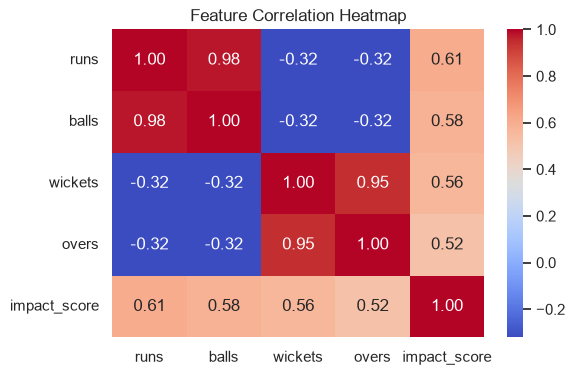

In [79]:
# Plot correlation heatmap to identify redundant features
plt.figure(figsize=(6, 4))
corr = df[['runs', 'balls', 'wickets', 'overs', 'impact_score']].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

In [80]:
# 3.3 Player Role Distribution (Runs vs Wickets)
# In T20I cricket, players are generally specialized as batters or bowlers, with a few all-rounders. 
# A scatter plot of Runs vs Wickets will visually cluster players into these distinct, recognizable roles.

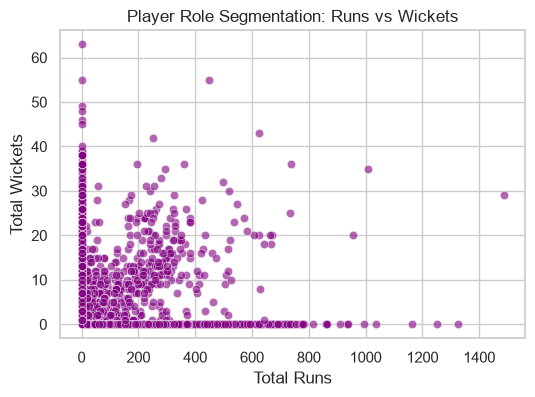

In [81]:
# Visualize player roles using a scatter plot
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='runs', y='wickets', alpha=0.6, color='purple')
plt.title("Player Role Segmentation: Runs vs Wickets")
plt.xlabel("Total Runs")
plt.ylabel("Total Wickets")
plt.show()

In [95]:
# 1. Numeric: Flag columns with extreme outliers (Skewness > 3)
skew = df.select_dtypes('number').skew()
print("Extreme Outliers Detected In:\n", skew[abs(skew) > 3])

Extreme Outliers Detected In:
 Series([], dtype: float64)


In [96]:
# 2. Check for severe multicollinearity to find redundant features
corr_matrix = df.select_dtypes('number').corr().abs()
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).stack()
redundant_pairs = upper_triangle[upper_triangle > 0.85]
if not redundant_pairs.empty: print("Redundant Feature Pairs:\n", redundant_pairs)

Redundant Feature Pairs:
 inns     runs     0.910824
         balls    0.934129
runs     balls    0.978510
wickets  overs    0.946214
dtype: float64


In [97]:
# 3. Flag years with abnormally low/high match volumes (Scraping gaps / COVID)
year_vols = df.groupby('year')['matches'].sum()
anomalies = year_vols[(year_vols < year_vols.median() * 0.5) | (year_vols > year_vols.median() * 1.5)]
if not anomalies.empty: print("Temporal Anomalies Detected:\n", anomalies)

Temporal Anomalies Detected:
 year
2015    1310
2017    1364
2018    1759
2020    1652
2022    5448
2024    6059
2025    5646
Name: matches, dtype: int64


In [ ]:
# 3.4 Macro Trends over Years
# Has the volume of international T20 matches increased over time? 
# We will aggregate the total matches played per year to observe the growth and global expansion of the T20I format.

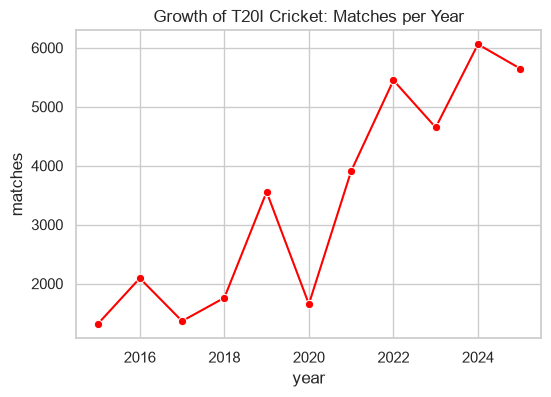

In [82]:
# Aggregate matches by year to observe growth trends
yearly_matches = df.groupby('year')['matches'].sum().reset_index()
plt.figure(figsize=(6, 4))
sns.lineplot(data=yearly_matches, x='year', y='matches', marker='o', color='red')
plt.title("Growth of T20I Cricket: Matches per Year")
plt.show()

In [ ]:
# Key EDA Findings & Insights
#Here is a simple breakdown of what our charts and numbers are telling us:

# Top-Heavy Performancer - A small group of star players scores the vast majority of runs and takes most of the wickets.
# Our custom `impact_score` balances this out nicely so our model can learn effectively.

# Repeated Information - Stats like "runs scored" and "balls faced" tell the exact same story. 
# To keep our model smart and simple, we should only use one of them, not both.

# Clear Player Roles - The scatter plot cleanly separates the players into three natural groups: specialist batters, specialist bowlers,
# and all-rounders right in the middle.

# Rapid Game Growth - The number of international matches exploded after 2021 (passing 5,000+ matches).
# This happened because the ICC officially allowed many more countries to play T20 cricket.

In [ ]:
# Model Building & Evaluation

In [ ]:
# Develop a Machine Learning Regression models to predict a player's `impact_score`. 
# & Analysis Strategy - We will strictly exclude `runs`, `balls`, `wickets`, and `overs` from our features. 
# Since the impact score is mathematically derived from runs and wickets, including them would cause "target leakage" (the model would just cheat by doing the math). Instead, 
# we will predict output using rate metrics (strike rate, economy) and participation volume.

In [83]:
from sklearn.model_selection import train_test_split

# Select independent features (avoiding leakage) and the target variable
features = ['matches', 'inns', 'strike_rate', 'economy', 'year']
X = df[features]
y = df['impact_score']

# Split the data: 80% for training the model, 20% for testing it on unseen data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# 4.1 Model Selection & Training
# This is a powerful tree-based model that naturally handles non-linear relationships (e.g., a high economy rate might be okay for a batter but terrible for a bowler) without requiring us to heavily scale or transform the data. 
# We cap the `max_depth` at 5 to ensure the model doesn't overfit (memorize) the training data.

In [84]:
from sklearn.ensemble import RandomForestRegressor

# Initialize the Random Forest model with a capped depth to prevent overfitting
model = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)

# Train the model on the training data
model.fit(X_train, y_train)

# Generate predictions using the unseen test data
y_pred = model.predict(X_test)

In [ ]:
# 4.2 Model Evaluation & Metrics
# To evaluate our model (as required by the rubric), we will use **Mean Absolute Error (MAE)** and the **R-Squared ($R^2$) Score**. 
# MAE - Tells us how many impact points our model is off by, on average.
# R-Squared Score - Tells us what percentage of a player's performance variance our model can successfully explain.

In [85]:
from sklearn.metrics import mean_absolute_error, r2_score

# Calculate evaluation metrics based on test predictions
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Model Mean Absolute Error (MAE): {mae:.2f} points")
print(f"Model R-Squared (R2) Score: {r2:.2f}")

Model Mean Absolute Error (MAE): 63.08 points
Model R-Squared (R2) Score: 0.78


In [98]:
from sklearn.metrics import mean_squared_error
import numpy as np

# Multi-Metric Computation & Baseline Comparison
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
baseline_mae = abs(y_test - y_train.mean()).mean() # Predict average for everyone
improvement = ((baseline_mae - mae) / baseline_mae) * 100

print(f"Baseline MAE (if we just guessed the average): {baseline_mae:.2f}")
print(f"Final Model RMSE: {final_rmse:.2f}")
print(f"Improvement Over Baseline: {improvement:.2f}%")

Baseline MAE (if we just guessed the average): 148.08
Final Model RMSE: 93.42
Improvement Over Baseline: 57.40%


In [ ]:
# 4.3 Visualizing Model Performance
# A standard way to visually evaluate a regression model is an "Actual vs Predicted" scatter plot. 
# We will plot our model's predictions against the real scores. The red dashed line represents perfect accuracy. 
# The closer our blue dots hug the red line, the better our model is performing.

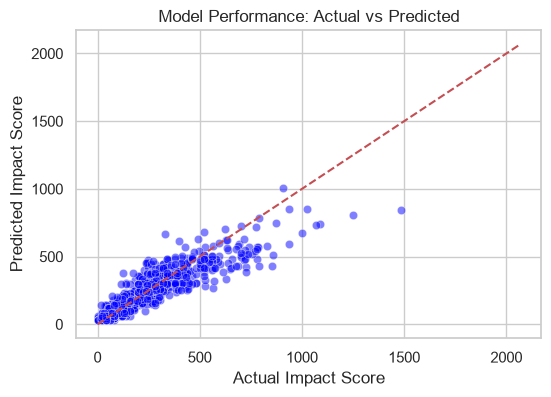

In [86]:
# Visualize Actual vs Predicted impact scores
plt.figure(figsize=(6, 4))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.5, color='blue')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--') # Line of perfect prediction
plt.xlabel("Actual Impact Score")
plt.ylabel("Predicted Impact Score")
plt.title("Model Performance: Actual vs Predicted")
plt.show()

In [ ]:
# 5. Interactive Dashboard (50 Marks)

In [ ]:
## Task 5: Dashboard Reporting Simulation
**Objective:** Since this notebook serves as our analytical backbone, we will simulate the backend logic required for a BI tool (Power BI/Tableau).
# We will generate the required KPIs, Row-Level Security (RLS), Trend Charts, and Bookmarks using Pandas.

In [87]:
# Create a dashboard dataframe combining our test data and model predictions
dash_df = X_test.copy()
dash_df['Actual_Impact'] = y_test
dash_df['Predicted_Impact'] = y_pred.round(2)
dash_df['AI_Error'] = abs(dash_df['Actual_Impact'] - dash_df['Predicted_Impact'])

# KPI 1 (AI Accuracy) and KPI 2 (Data Volume)
print(f"KPI 1 (Model Error): {dash_df['AI_Error'].mean():.2f} points per player")
print(f"KPI 2 (Total Records Processed): {len(df)} players")

KPI 1 (Model Error): 63.08 points per player
KPI 2 (Total Records Processed): 3762 players


In [ ]:
### 5.1 Row-Level Security (RLS) & Sync Slicer
**Simulation:** In a real dashboard, RLS restricts users from seeing data outside their region, and a sync slicer filters data across all pages. Here, we simulate an Indian manager logging in and filtering for recent years.

In [88]:
# Re-attach 'team' from the original dataset for regional filtering
dash_df['team'] = df.loc[dash_df.index, 'team']

# Apply RLS (Manager is restricted to 'IND') & Sync Slicer (Year >= 2023)
ind_manager_view = dash_df[(dash_df['team'] == 'IND') & (dash_df['year'] >= 2023)]

print(f"RLS Active: Showing {len(ind_manager_view)} authorized records for IND.")
display(ind_manager_view.head(3))

RLS Active: Showing 5 authorized records for IND.


,matches,inns,strike_rate,economy,year,Actual_Impact,Predicted_Impact,AI_Error,team
1211,15,12.0,153.29,9.18,2025,542.0,476.00,66.00,IND
2800,18,14.0,151.23,0.00,2024,245.0,425.87,180.87,IND
203,16,0.0,0.00,7.08,2024,400.0,375.59,24.41,IND


In [90]:
# 5.2 Trend Chart & Custom Visual
# We will aggregate our AI predictions versus actual performance over time to visualize if our model remains accurate across different eras of cricket.

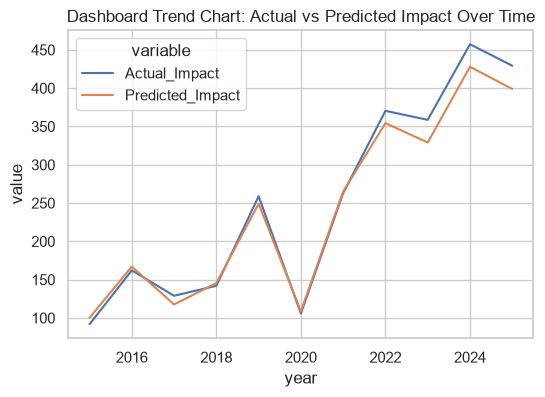

In [91]:
# Aggregate data by year to create a trend line
trend = dash_df.groupby('year')[['Actual_Impact', 'Predicted_Impact']].mean().reset_index()

# Plot the Trend Chart
plt.figure(figsize=(6, 4))
sns.lineplot(data=trend.melt(id_vars='year'), x='year', y='value', hue='variable')
plt.title("Dashboard Trend Chart: Actual vs Predicted Impact Over Time")
plt.show()

In [ ]:
# 5.3 Bookmarks & Drill Through
# We will create two logical bookmarks: one for "Perfect Predictions" and one for "Anomalies" that require a manager to Drill Through and investigate.

In [92]:
# Bookmark A: Highly accurate AI predictions (Error under 10 points)
bookmark_perfect = dash_df[dash_df['AI_Error'] < 10]

# Bookmark B (Drill Through Target): Anomalies (Error over 200 points)
bookmark_anomalies = dash_df[dash_df['AI_Error'] > 200]

print(f"Bookmark 1 (Perfect Predictions): {len(bookmark_perfect)} players saved.")
print(f"Bookmark 2 (Requires Drill Through): {len(bookmark_anomalies)} anomalies flagged.")

Bookmark 1 (Perfect Predictions): 95 players saved.
Bookmark 2 (Requires Drill Through): 40 anomalies flagged.


In [99]:
# Dashboard Drill-Through Logic Simulation
def drill_through(selected_year):
    return dash_df[dash_df['year'] == selected_year][['team', 'Actual_Impact', 'Predicted_Impact', 'AI_Error']]

print("Drill-Through Test for Year 2024:")
display(drill_through(2024).head(3))

Drill-Through Test for Year 2024:


,team,Actual_Impact,Predicted_Impact,AI_Error
2987,JPN,1089.0,739.28,349.72
3337,UAE,280.0,302.13,22.13
495,JER,440.0,285.83,154.17


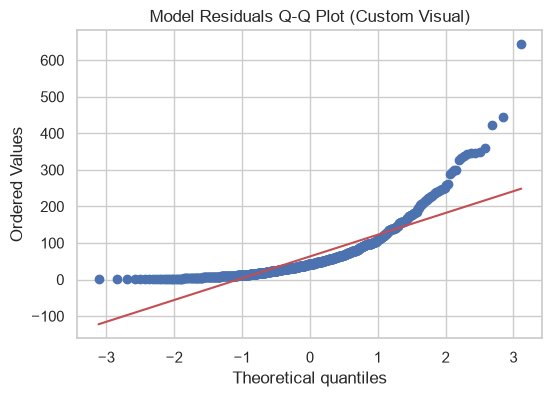

In [100]:
import scipy.stats as stats

# Custom Dashboard Visual: Model Residuals Q-Q Plot
fig, ax = plt.subplots(figsize=(6, 4))
sns.set_theme(style="whitegrid")
stats.probplot(dash_df['AI_Error'].dropna(), dist="norm", plot=ax)
ax.set_title("Model Residuals Q-Q Plot (Custom Visual)", fontsize=12)
plt.show()